In [2]:
# ============================================
# STEP 1: IMPORT LIBRARIES
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# ============================================
# STEP 2: LOAD DATASET
# ============================================

df = pd.read_csv("hospital_opd_waiting_time_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print("Shape:", df.shape)

Shape: (1000, 9)


In [7]:
df.head()

,Patient_ID,Department,Appointment_Time,Registration_Time,Consultation_Time,Discharge_Time,Doctor,Day,Appointment_Type
0,P0897,Dermatology,2026-07-01 08:15:00,2026-07-01 08:26:00,2026-07-01 08:40:00,2026-07-01 08:53:00,Dr. Nisha,Wednesday,Follow-up
1,P0761,Pediatrics,2026-07-01 08:30:00,2026-07-01 08:33:00,2026-07-01 08:57:00,2026-07-01 09:08:00,Dr. Ravi,Wednesday,Follow-up
2,P0191,General Medicine,2026-07-01 09:00:00,2026-07-01 09:16:00,2026-07-01 09:57:00,2026-07-01 10:26:00,Dr. Divya,Wednesday,New
3,P0076,Orthopedics,2026-07-01 09:15:00,2026-07-01 09:27:00,2026-07-01 10:17:00,2026-07-01 10:45:00,Dr. Priya,Wednesday,New
4,P0505,Cardiology,2026-07-01 09:45:00,2026-07-01 10:05:00,2026-07-01 10:30:00,2026-07-01 10:54:00,Dr. Arun,Wednesday,New


In [8]:
# ============================================
# STEP 3: BASIC DATASET INFORMATION
# ============================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of rows: 1000
Number of columns: 9

Column Names:
['Patient_ID', 'Department', 'Appointment_Time', 'Registration_Time', 'Consultation_Time', 'Discharge_Time', 'Doctor', 'Day', 'Appointment_Type']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Patient_ID         1000 non-null   object
 1   Department         1000 non-null   object
 2   Appointment_Time   1000 non-null   object
 3   Registration_Time  1000 non-null   object
 4   Consultation_Time  1000 non-null   object
 5   Discharge_Time     1000 non-null   object
 6   Doctor             1000 non-null   object
 7   Day                1000 non-null   object
 8   Appointment_Type   1000 non-null   object
dtypes: object(9)
memory usage: 70.4+ KB


In [9]:
# ============================================
# STEP 3: BASIC DATASET INFORMATION
# ============================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of rows: 1000
Number of columns: 9

Column Names:
['Patient_ID', 'Department', 'Appointment_Time', 'Registration_Time', 'Consultation_Time', 'Discharge_Time', 'Doctor', 'Day', 'Appointment_Type']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Patient_ID         1000 non-null   object
 1   Department         1000 non-null   object
 2   Appointment_Time   1000 non-null   object
 3   Registration_Time  1000 non-null   object
 4   Consultation_Time  1000 non-null   object
 5   Discharge_Time     1000 non-null   object
 6   Doctor             1000 non-null   object
 7   Day                1000 non-null   object
 8   Appointment_Type   1000 non-null   object
dtypes: object(9)
memory usage: 70.4+ KB


In [10]:
# ============================================
# STEP 5: CHECK MISSING VALUES
# ============================================

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Patient_ID           0
Department           0
Appointment_Time     0
Registration_Time    0
Consultation_Time    0
Discharge_Time       0
Doctor               0
Day                  0
Appointment_Type     0
dtype: int64


In [11]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing value percentage:")
print(missing_percentage)


Missing value percentage:
Patient_ID           0.0
Department           0.0
Appointment_Time     0.0
Registration_Time    0.0
Consultation_Time    0.0
Discharge_Time       0.0
Doctor               0.0
Day                  0.0
Appointment_Type     0.0
dtype: float64


In [12]:
# ============================================
# STEP 6: CHECK DUPLICATES
# ============================================

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [13]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (1000, 9)


In [14]:
# ============================================
# STEP 7: CONVERT TIMESTAMP COLUMNS
# ============================================

time_columns = [
    "Appointment_Time",
    "Registration_Time",
    "Consultation_Time",
    "Discharge_Time"
]

for col in time_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print("Timestamp conversion completed.")

df[time_columns].head()

Timestamp conversion completed.


,Appointment_Time,Registration_Time,Consultation_Time,Discharge_Time
0,2026-07-01 08:15:00,2026-07-01 08:26:00,2026-07-01 08:40:00,2026-07-01 08:53:00
1,2026-07-01 08:30:00,2026-07-01 08:33:00,2026-07-01 08:57:00,2026-07-01 09:08:00
2,2026-07-01 09:00:00,2026-07-01 09:16:00,2026-07-01 09:57:00,2026-07-01 10:26:00
3,2026-07-01 09:15:00,2026-07-01 09:27:00,2026-07-01 10:17:00,2026-07-01 10:45:00
4,2026-07-01 09:45:00,2026-07-01 10:05:00,2026-07-01 10:30:00,2026-07-01 10:54:00


In [ ]:
# ============================================
# STEP 8: TIMESTAMP VALIDATION
# ============================================

invalid_order = (
    (df["Registration_Time"] < df["Appointment_Time"]) |
    (df["Consultation_Time"] < df["Registration_Time"]) |
    (df["Discharge_Time"] < df["Consultation_Time"])
)

print("Number of records with invalid timestamp order:",
      invalid_order.sum())

In [15]:
# ============================================
# STEP 9: CHECK CATEGORICAL VALUES
# ============================================

print("Departments:")
print(df["Department"].unique())

print("\nDoctors:")
print(df["Doctor"].unique())

print("\nDays:")
print(df["Day"].unique())

print("\nAppointment Types:")
print(df["Appointment_Type"].unique())

Departments:
['Dermatology' 'Pediatrics' 'General Medicine' 'Orthopedics' 'Cardiology'
 'Neurology']

Doctors:
['Dr. Nisha' 'Dr. Ravi' 'Dr. Divya' 'Dr. Priya' 'Dr. Arun' 'Dr. Karthik'
 'Dr. Anitha' 'Dr. Meena' 'Dr. Kumar' 'Dr. Raj' 'Dr. Lakshmi' 'Dr. Suresh']

Days:
['Wednesday' 'Thursday' 'Friday' 'Saturday' 'Sunday' 'Monday' 'Tuesday']

Appointment Types:
['Follow-up' 'New' 'Emergency']


In [16]:
# ============================================
# STEP 10: PATIENT ID VALIDATION
# ============================================

duplicate_patient_ids = df["Patient_ID"].duplicated().sum()

print("Duplicate Patient IDs:", duplicate_patient_ids)
print("Unique Patient IDs:", df["Patient_ID"].nunique())

Duplicate Patient IDs: 0
Unique Patient IDs: 1000


In [17]:
# ============================================
# STEP 11: REGISTRATION WAITING TIME
# ============================================

df["Registration_Wait"] = (
    df["Registration_Time"] -
    df["Appointment_Time"]
).dt.total_seconds() / 60

df["Registration_Wait"] = df["Registration_Wait"].round(2)

df[[
    "Patient_ID",
    "Appointment_Time",
    "Registration_Time",
    "Registration_Wait"
]].head()

,Patient_ID,Appointment_Time,Registration_Time,Registration_Wait
0,P0897,2026-07-01 08:15:00,2026-07-01 08:26:00,11.0
1,P0761,2026-07-01 08:30:00,2026-07-01 08:33:00,3.0
2,P0191,2026-07-01 09:00:00,2026-07-01 09:16:00,16.0
3,P0076,2026-07-01 09:15:00,2026-07-01 09:27:00,12.0
4,P0505,2026-07-01 09:45:00,2026-07-01 10:05:00,20.0


In [18]:
# ============================================
# STEP 12: DOCTOR WAITING TIME
# ============================================

df["Doctor_Wait"] = (
    df["Consultation_Time"] -
    df["Registration_Time"]
).dt.total_seconds() / 60

df["Doctor_Wait"] = df["Doctor_Wait"].round(2)

df[[
    "Patient_ID",
    "Registration_Time",
    "Consultation_Time",
    "Doctor_Wait"
]].head()

,Patient_ID,Registration_Time,Consultation_Time,Doctor_Wait
0,P0897,2026-07-01 08:26:00,2026-07-01 08:40:00,14.0
1,P0761,2026-07-01 08:33:00,2026-07-01 08:57:00,24.0
2,P0191,2026-07-01 09:16:00,2026-07-01 09:57:00,41.0
3,P0076,2026-07-01 09:27:00,2026-07-01 10:17:00,50.0
4,P0505,2026-07-01 10:05:00,2026-07-01 10:30:00,25.0


In [19]:
# ============================================
# STEP 13: TOTAL WAITING TIME
# ============================================

df["Total_Wait"] = (
    df["Consultation_Time"] -
    df["Appointment_Time"]
).dt.total_seconds() / 60

df["Total_Wait"] = df["Total_Wait"].round(2)

df[[
    "Patient_ID",
    "Registration_Wait",
    "Doctor_Wait",
    "Total_Wait"
]].head()

,Patient_ID,Registration_Wait,Doctor_Wait,Total_Wait
0,P0897,11.0,14.0,25.0
1,P0761,3.0,24.0,27.0
2,P0191,16.0,41.0,57.0
3,P0076,12.0,50.0,62.0
4,P0505,20.0,25.0,45.0


In [20]:
# ============================================
# STEP 14: CONSULTATION DURATION
# ============================================

df["Consultation_Duration"] = (
    df["Discharge_Time"] -
    df["Consultation_Time"]
).dt.total_seconds() / 60

df["Consultation_Duration"] = df["Consultation_Duration"].round(2)

df[[
    "Patient_ID",
    "Consultation_Duration"
]].head()

,Patient_ID,Consultation_Duration
0,P0897,13.0
1,P0761,11.0
2,P0191,29.0
3,P0076,28.0
4,P0505,24.0


In [21]:
# ============================================
# STEP 14: CONSULTATION DURATION
# ============================================

df["Consultation_Duration"] = (
    df["Discharge_Time"] -
    df["Consultation_Time"]
).dt.total_seconds() / 60

df["Consultation_Duration"] = df["Consultation_Duration"].round(2)

df[[
    "Patient_ID",
    "Consultation_Duration"
]].head()

,Patient_ID,Consultation_Duration
0,P0897,13.0
1,P0761,11.0
2,P0191,29.0
3,P0076,28.0
4,P0505,24.0


In [22]:
# ============================================
# STEP 15: WAITING TIME VALIDATION
# ============================================

print("Negative Registration Wait:",
      (df["Registration_Wait"] < 0).sum())

print("Negative Doctor Wait:",
      (df["Doctor_Wait"] < 0).sum())

print("Negative Total Wait:",
      (df["Total_Wait"] < 0).sum())

Negative Registration Wait: 0
Negative Doctor Wait: 0
Negative Total Wait: 0


In [23]:
# ============================================
# STEP 16: DESCRIPTIVE STATISTICS
# ============================================

waiting_columns = [
    "Registration_Wait",
    "Doctor_Wait",
    "Total_Wait",
    "Consultation_Duration"
]

df[waiting_columns].describe()

,Registration_Wait,Doctor_Wait,Total_Wait,Consultation_Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,12.014000,38.945000,50.959000,20.469000
std,5.807024,13.651093,15.630407,7.582911
min,2.000000,5.000000,10.000000,8.000000
25%,8.000000,29.000000,40.000000,15.000000
50%,12.000000,39.000000,51.000000,20.000000
75%,16.000000,48.000000,62.000000,26.000000
max,32.000000,87.000000,115.000000,42.000000


In [24]:
# ============================================
# STEP 17: OVERALL WAITING TIME SUMMARY
# ============================================

for col in waiting_columns:
    print("\n", col)
    print("Mean   :", round(df[col].mean(), 2), "minutes")
    print("Median :", round(df[col].median(), 2), "minutes")
    print("Minimum:", round(df[col].min(), 2), "minutes")
    print("Maximum:", round(df[col].max(), 2), "minutes")
    print("Std Dev:", round(df[col].std(), 2), "minutes")


 Registration_Wait
Mean   : 12.01 minutes
Median : 12.0 minutes
Minimum: 2.0 minutes
Maximum: 32.0 minutes
Std Dev: 5.81 minutes

 Doctor_Wait
Mean   : 38.94 minutes
Median : 39.0 minutes
Minimum: 5.0 minutes
Maximum: 87.0 minutes
Std Dev: 13.65 minutes

 Total_Wait
Mean   : 50.96 minutes
Median : 51.0 minutes
Minimum: 10.0 minutes
Maximum: 115.0 minutes
Std Dev: 15.63 minutes

 Consultation_Duration
Mean   : 20.47 minutes
Median : 20.0 minutes
Minimum: 8.0 minutes
Maximum: 42.0 minutes
Std Dev: 7.58 minutes


In [25]:
# ============================================
# STEP 18: DEPARTMENT-WISE WAITING TIME
# ============================================

department_analysis = df.groupby("Department").agg(
    Patients=("Patient_ID", "count"),
    Avg_Registration_Wait=("Registration_Wait", "mean"),
    Avg_Doctor_Wait=("Doctor_Wait", "mean"),
    Avg_Total_Wait=("Total_Wait", "mean"),
    Median_Total_Wait=("Total_Wait", "median"),
    Max_Total_Wait=("Total_Wait", "max")
).round(2)

department_analysis = department_analysis.sort_values(
    "Avg_Total_Wait",
    ascending=False
)

display(department_analysis)

,Patients,Avg_Registration_Wait,Avg_Doctor_Wait,Avg_Total_Wait,Median_Total_Wait,Max_Total_Wait
Department,,,,,,
General Medicine,203,12.25,44.19,56.44,56.0,115.0
Neurology,149,12.30,40.10,52.40,54.0,103.0
Cardiology,174,11.50,40.61,52.11,50.0,86.0
Orthopedics,174,11.99,38.21,50.21,48.0,104.0
Dermatology,128,12.24,34.90,47.14,49.0,80.0
Pediatrics,172,11.85,33.82,45.67,48.0,78.0


In [26]:
# ============================================
# STEP 18: DEPARTMENT-WISE WAITING TIME
# ============================================

department_analysis = df.groupby("Department").agg(
    Patients=("Patient_ID", "count"),
    Avg_Registration_Wait=("Registration_Wait", "mean"),
    Avg_Doctor_Wait=("Doctor_Wait", "mean"),
    Avg_Total_Wait=("Total_Wait", "mean"),
    Median_Total_Wait=("Total_Wait", "median"),
    Max_Total_Wait=("Total_Wait", "max")
).round(2)

department_analysis = department_analysis.sort_values(
    "Avg_Total_Wait",
    ascending=False
)

display(department_analysis)

,Patients,Avg_Registration_Wait,Avg_Doctor_Wait,Avg_Total_Wait,Median_Total_Wait,Max_Total_Wait
Department,,,,,,
General Medicine,203,12.25,44.19,56.44,56.0,115.0
Neurology,149,12.30,40.10,52.40,54.0,103.0
Cardiology,174,11.50,40.61,52.11,50.0,86.0
Orthopedics,174,11.99,38.21,50.21,48.0,104.0
Dermatology,128,12.24,34.90,47.14,49.0,80.0
Pediatrics,172,11.85,33.82,45.67,48.0,78.0


In [27]:
# ============================================
# STEP 19: HIGH-WAIT DEPARTMENT ANALYSIS
# ============================================

department_consistency = df.groupby("Department").agg(
    Avg_Wait=("Total_Wait", "mean"),
    Median_Wait=("Total_Wait", "median"),
    Std_Dev=("Total_Wait", "std"),
    P75_Wait=("Total_Wait", lambda x: x.quantile(0.75)),
    P90_Wait=("Total_Wait", lambda x: x.quantile(0.90))
).round(2)

department_consistency = department_consistency.sort_values(
    "Avg_Wait",
    ascending=False
)

display(department_consistency)

,Avg_Wait,Median_Wait,Std_Dev,P75_Wait,P90_Wait
Department,,,,,
General Medicine,56.44,56.0,15.79,66.0,75.0
Neurology,52.40,54.0,15.34,61.0,71.2
Cardiology,52.11,50.0,13.85,62.0,72.0
Orthopedics,50.21,48.0,16.48,63.0,72.0
Dermatology,47.14,49.0,15.48,58.0,65.3
Pediatrics,45.67,48.0,14.30,55.0,63.9


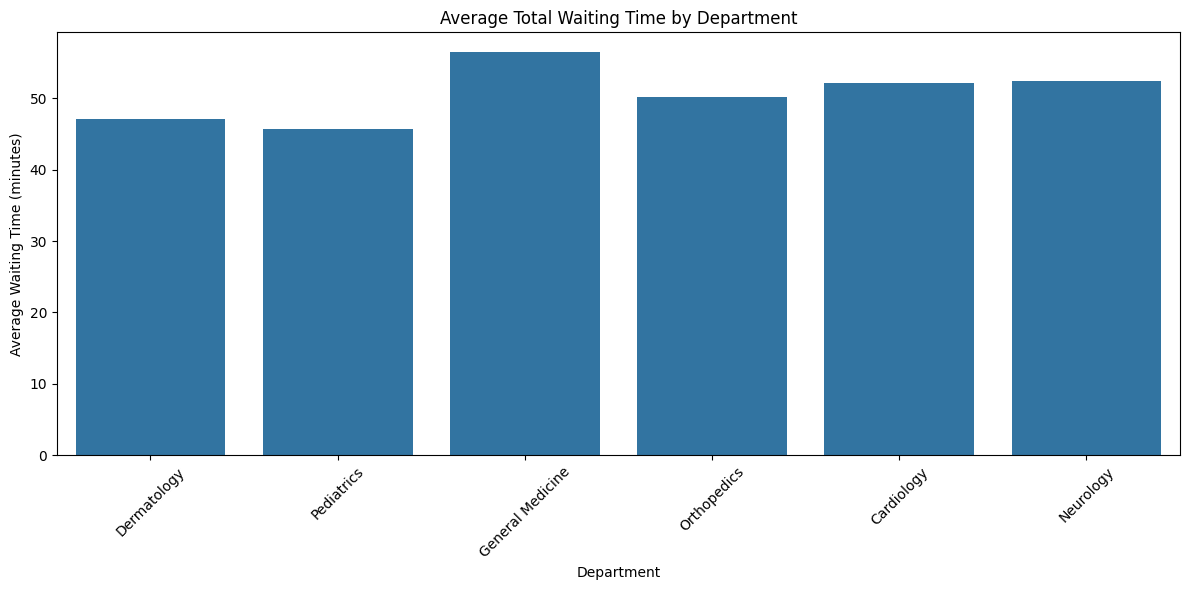

In [28]:
# ============================================
# VISUALIZATION 1
# ============================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Department",
    y="Total_Wait",
    estimator="mean",
    errorbar=None
)

plt.title("Average Total Waiting Time by Department")
plt.xlabel("Department")
plt.ylabel("Average Waiting Time (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

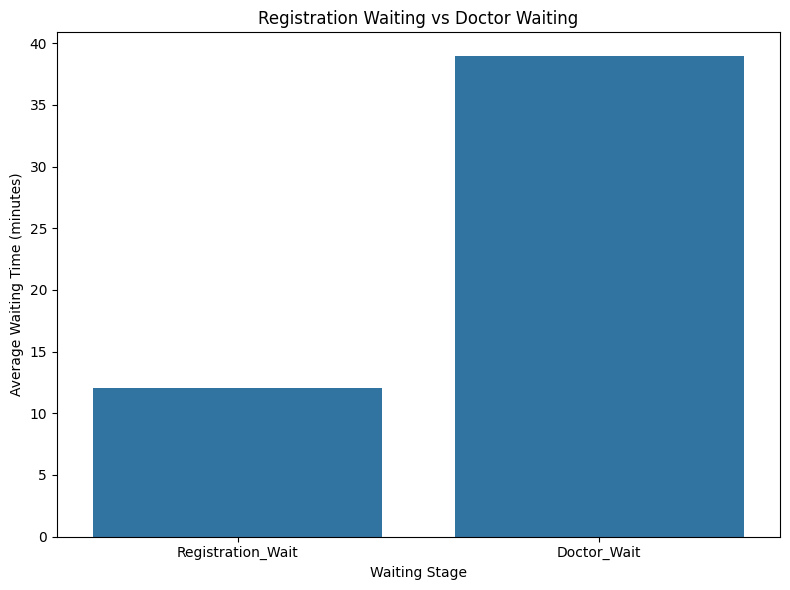

In [29]:
# ============================================
# VISUALIZATION 2
# ============================================

waiting_comparison = df[
    ["Registration_Wait", "Doctor_Wait"]
].mean()

plt.figure(figsize=(8, 6))

sns.barplot(
    x=waiting_comparison.index,
    y=waiting_comparison.values
)

plt.title("Registration Waiting vs Doctor Waiting")
plt.xlabel("Waiting Stage")
plt.ylabel("Average Waiting Time (minutes)")

plt.tight_layout()
plt.show()

In [30]:
# ============================================
# STEP 22: APPOINTMENT HOUR
# ============================================

df["Appointment_Hour"] = df["Appointment_Time"].dt.hour

hour_analysis = df.groupby("Appointment_Hour").agg(
    Patients=("Patient_ID", "count"),
    Avg_Wait=("Total_Wait", "mean")
).round(2)

display(hour_analysis)

,Patients,Avg_Wait
Appointment_Hour,,
8,78,40.83
9,141,57.00
10,196,57.43
11,203,57.52
12,131,45.66
13,80,46.51
14,72,41.07
15,54,43.69
16,45,39.69


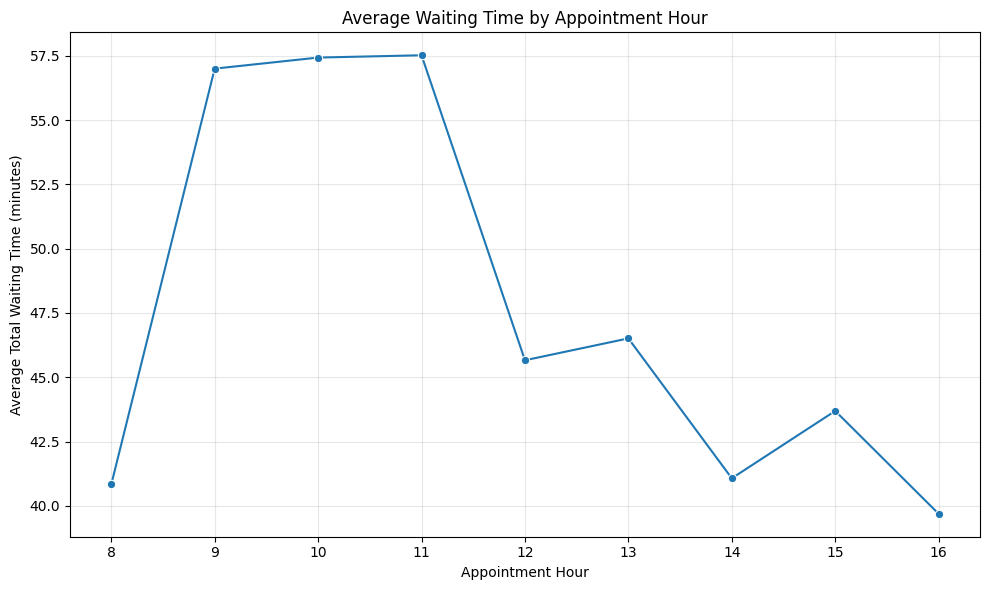

In [31]:
# ============================================
# VISUALIZATION 3
# ============================================

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=hour_analysis.reset_index(),
    x="Appointment_Hour",
    y="Avg_Wait",
    marker="o"
)

plt.title("Average Waiting Time by Appointment Hour")
plt.xlabel("Appointment Hour")
plt.ylabel("Average Total Waiting Time (minutes)")
plt.xticks(hour_analysis.index)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

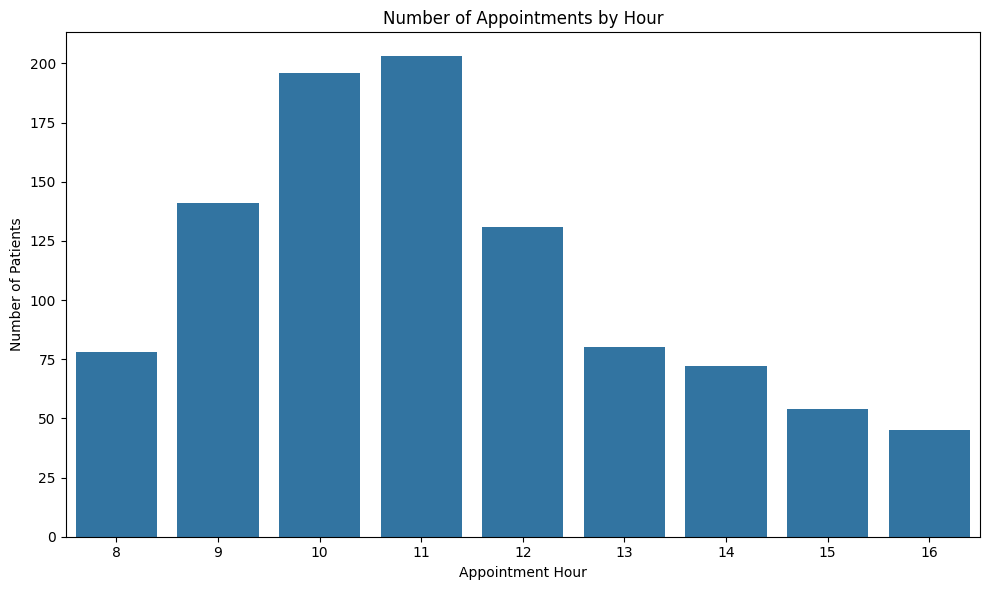

In [32]:
# ============================================
# STEP 24: APPOINTMENT VOLUME BY HOUR
# ============================================

hour_volume = df.groupby("Appointment_Hour").size()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=hour_volume.index,
    y=hour_volume.values
)

plt.title("Number of Appointments by Hour")
plt.xlabel("Appointment Hour")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [33]:
# ============================================
# STEP 25: WEEKDAY VS WEEKEND
# ============================================

df["Day_Type"] = df["Day"].apply(
    lambda x: "Weekend"
    if x in ["Saturday", "Sunday"]
    else "Weekday"
)

weekday_weekend = df.groupby("Day_Type").agg(
    Patients=("Patient_ID", "count"),
    Avg_Registration_Wait=("Registration_Wait", "mean"),
    Avg_Doctor_Wait=("Doctor_Wait", "mean"),
    Avg_Total_Wait=("Total_Wait", "mean")
).round(2)

display(weekday_weekend)

,Patients,Avg_Registration_Wait,Avg_Doctor_Wait,Avg_Total_Wait
Day_Type,,,,
Weekday,712,12.31,40.70,53.01
Weekend,288,11.28,34.61,45.89


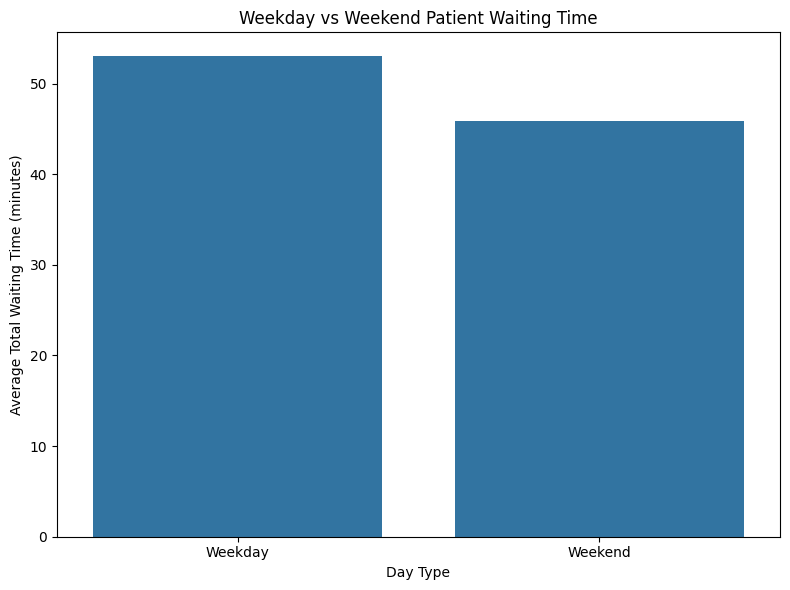

In [34]:
# ============================================
# VISUALIZATION 4
# ============================================

plt.figure(figsize=(8, 6))

sns.barplot(
    data=df,
    x="Day_Type",
    y="Total_Wait",
    estimator="mean",
    errorbar=None
)

plt.title("Weekday vs Weekend Patient Waiting Time")
plt.xlabel("Day Type")
plt.ylabel("Average Total Waiting Time (minutes)")

plt.tight_layout()
plt.show()

In [35]:
# ============================================
# STEP 27: APPOINTMENT TYPE ANALYSIS
# ============================================

appointment_analysis = df.groupby("Appointment_Type").agg(
    Patients=("Patient_ID", "count"),
    Avg_Registration_Wait=("Registration_Wait", "mean"),
    Avg_Doctor_Wait=("Doctor_Wait", "mean"),
    Avg_Total_Wait=("Total_Wait", "mean")
).round(2)

display(appointment_analysis)

,Patients,Avg_Registration_Wait,Avg_Doctor_Wait,Avg_Total_Wait
Appointment_Type,,,,
Emergency,100,13.84,52.82,66.66
Follow-up,483,11.72,36.32,48.04
New,417,11.91,38.66,50.58


In [36]:
# ============================================
# STEP 28: CREATE HIGH-WAIT TARGET
# ============================================

WAIT_THRESHOLD = 60

df["High_Wait"] = np.where(
    df["Total_Wait"] > WAIT_THRESHOLD,
    1,
    0
)

print("High-wait threshold:", WAIT_THRESHOLD, "minutes")

print("\nHigh-Wait Distribution:")
print(df["High_Wait"].value_counts())

print("\nPercentage:")
print(df["High_Wait"].value_counts(normalize=True) * 100)

High-wait threshold: 60 minutes

High-Wait Distribution:
High_Wait
0    732
1    268
Name: count, dtype: int64

Percentage:
High_Wait
0    73.2
1    26.8
Name: proportion, dtype: float64


In [37]:
# ============================================
# STEP 29: HIGH-WAIT RATE BY DEPARTMENT
# ============================================

high_wait_department = df.groupby("Department").agg(
    Total_Patients=("Patient_ID", "count"),
    High_Wait_Patients=("High_Wait", "sum"),
    High_Wait_Percentage=("High_Wait", "mean")
)

high_wait_department["High_Wait_Percentage"] *= 100

high_wait_department = high_wait_department.round(2)

high_wait_department = high_wait_department.sort_values(
    "High_Wait_Percentage",
    ascending=False
)

display(high_wait_department)

,Total_Patients,High_Wait_Patients,High_Wait_Percentage
Department,,,
General Medicine,203,79,38.92
Orthopedics,174,50,28.74
Cardiology,174,47,27.01
Neurology,149,40,26.85
Dermatology,128,25,19.53
Pediatrics,172,27,15.70


In [38]:
# ============================================
# STEP 30: MACHINE LEARNING FEATURES
# ============================================

features = [
    "Department",
    "Doctor",
    "Day",
    "Appointment_Type",
    "Appointment_Hour",
    "Day_Type"
]

X = df[features]
y = df["High_Wait"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['Department', 'Doctor', 'Day', 'Appointment_Type', 'Appointment_Hour', 'Day_Type']

Target:
High_Wait


In [39]:
# ============================================
# STEP 31: TRAIN TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


In [40]:
# ============================================
# STEP 32: PREPROCESSING
# ============================================

categorical_features = [
    "Department",
    "Doctor",
    "Day",
    "Appointment_Type",
    "Day_Type"
]

numeric_features = [
    "Appointment_Hour"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [41]:
# ============================================
# STEP 33: RANDOM FOREST MODEL
# ============================================

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", random_forest)
    ]
)

print("Random Forest model created.")

Random Forest model created.


In [42]:
# ============================================
# STEP 34: TRAIN RANDOM FOREST
# ============================================

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [43]:
# ============================================
# STEP 34: TRAIN RANDOM FOREST
# ============================================

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [45]:
# ============================================
# CREATE PREDICTIONS
# ============================================

y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))
print("First 20 predictions:")
print(y_pred[:20])

Predictions generated successfully!
Number of predictions: 200
First 20 predictions:
[0 0 0 0 0 1 0 1 0 1 0 0 1 1 0 0 0 0 0 0]


In [46]:
# ============================================
# MODEL EVALUATION
# ============================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("RANDOM FOREST MODEL EVALUATION")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

RANDOM FOREST MODEL EVALUATION
--------------------------------
Accuracy : 0.705
Precision: 0.451
Recall   : 0.4259
F1 Score : 0.4381


In [47]:
# ============================================
# STEP 37: CLASSIFICATION REPORT
# ============================================

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal Wait", "High Wait"],
    zero_division=0
))

              precision    recall  f1-score   support

 Normal Wait       0.79      0.81      0.80       146
   High Wait       0.45      0.43      0.44        54

    accuracy                           0.70       200
   macro avg       0.62      0.62      0.62       200
weighted avg       0.70      0.70      0.70       200



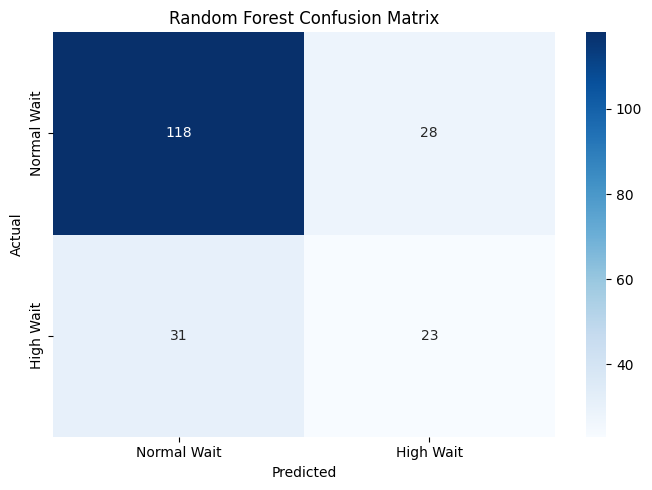

In [48]:
# ============================================
# STEP 38: CONFUSION MATRIX
# ============================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal Wait", "High Wait"],
    yticklabels=["Normal Wait", "High Wait"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [49]:
# ============================================
# STEP 39: FEATURE IMPORTANCE
# ============================================

# Get transformed feature names
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get Random Forest importance
importances = model.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
30,numeric__Appointment_Hour,0.369968
25,categorical__Appointment_Type_Emergency,0.059822
22,categorical__Day_Thursday,0.038871
26,categorical__Appointment_Type_Follow-up,0.037595
27,categorical__Appointment_Type_New,0.037485
19,categorical__Day_Monday,0.036138
24,categorical__Day_Wednesday,0.030919
18,categorical__Day_Friday,0.029388
23,categorical__Day_Tuesday,0.027280
5,categorical__Department_Pediatrics,0.019058


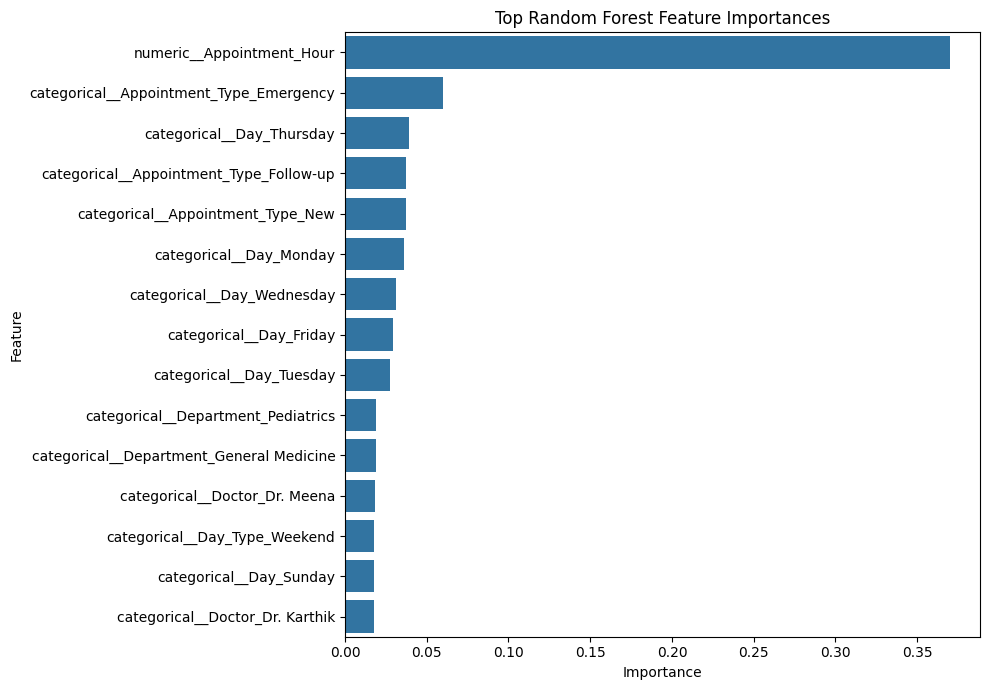

In [50]:
# ============================================
# STEP 40: FEATURE IMPORTANCE VISUALIZATION
# ============================================

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [51]:
# ============================================
# STEP 41: KEY ANALYTICAL VALUES
# ============================================

highest_department = department_analysis.index[0]
highest_department_wait = department_analysis.iloc[0]["Avg_Total_Wait"]

lowest_department = department_analysis.index[-1]
lowest_department_wait = department_analysis.iloc[-1]["Avg_Total_Wait"]

registration_avg = df["Registration_Wait"].mean()
doctor_avg = df["Doctor_Wait"].mean()

highest_hour = hour_analysis["Avg_Wait"].idxmax()
highest_hour_wait = hour_analysis["Avg_Wait"].max()

weekday_wait = weekday_weekend.loc["Weekday", "Avg_Total_Wait"]
weekend_wait = weekday_weekend.loc["Weekend", "Avg_Total_Wait"]

highest_appointment_type = appointment_analysis["Avg_Total_Wait"].idxmax()
highest_appointment_type_wait = appointment_analysis.loc[
    highest_appointment_type,
    "Avg_Total_Wait"
]

highest_high_wait_department = high_wait_department.index[0]
highest_high_wait_percentage = high_wait_department.iloc[0]["High_Wait_Percentage"]

print("KEY FINDINGS")
print("============")

print(
    f"1. {highest_department} has the highest average total waiting "
    f"time at {highest_department_wait:.2f} minutes."
)

print(
    f"2. {lowest_department} has the lowest average total waiting "
    f"time at {lowest_department_wait:.2f} minutes."
)

print(
    f"3. Average registration waiting time is {registration_avg:.2f} minutes, "
    f"while average doctor waiting time is {doctor_avg:.2f} minutes."
)

print(
    f"4. The appointment hour with the highest average waiting time "
    f"is {highest_hour}:00, with {highest_hour_wait:.2f} minutes."
)

print(
    f"5. Average weekday waiting time is {weekday_wait:.2f} minutes, "
    f"compared with {weekend_wait:.2f} minutes on weekends."
)

print(
    f"6. {highest_appointment_type} appointments have the highest "
    f"average waiting time at {highest_appointment_type_wait:.2f} minutes."
)

print(
    f"7. {highest_high_wait_department} has the highest proportion "
    f"of high-wait patients at {highest_high_wait_percentage:.2f}%."
)

KEY FINDINGS
1. General Medicine has the highest average total waiting time at 56.44 minutes.
2. Pediatrics has the lowest average total waiting time at 45.67 minutes.
3. Average registration waiting time is 12.01 minutes, while average doctor waiting time is 38.95 minutes.
4. The appointment hour with the highest average waiting time is 11:00, with 57.52 minutes.
5. Average weekday waiting time is 53.01 minutes, compared with 45.89 minutes on weekends.
6. Emergency appointments have the highest average waiting time at 66.66 minutes.
7. General Medicine has the highest proportion of high-wait patients at 38.92%.


In [52]:
# ============================================
# STEP 42: BOTTLENECK IDENTIFICATION
# ============================================

if doctor_avg > registration_avg:
    bottleneck = "Doctor consultation waiting"
else:
    bottleneck = "Registration waiting"

print("MAIN BOTTLENECK")
print("----------------")
print(
    f"The larger average waiting component is: {bottleneck}"
)

print(f"\nAverage Registration Wait: {registration_avg:.2f} minutes")
print(f"Average Doctor Wait: {doctor_avg:.2f} minutes")

MAIN BOTTLENECK
----------------
The larger average waiting component is: Doctor consultation waiting

Average Registration Wait: 12.01 minutes
Average Doctor Wait: 38.95 minutes


In [53]:
# ============================================
# STEP 43: SCHEDULING CONGESTION ANALYSIS
# ============================================

scheduling_analysis = df.groupby("Appointment_Hour").agg(
    Patient_Count=("Patient_ID", "count"),
    Average_Wait=("Total_Wait", "mean")
).round(2)

print("Scheduling Analysis:")
display(scheduling_analysis)

correlation = scheduling_analysis[
    ["Patient_Count", "Average_Wait"]
].corr().iloc[0, 1]

print(
    f"\nCorrelation between appointment volume and average waiting time: "
    f"{correlation:.3f}"
)

Scheduling Analysis:


,Patient_Count,Average_Wait
Appointment_Hour,,
8,78,40.83
9,141,57.00
10,196,57.43
11,203,57.52
12,131,45.66
13,80,46.51
14,72,41.07
15,54,43.69
16,45,39.69



Correlation between appointment volume and average waiting time: 0.908


In [54]:
# ============================================
# STEP 44: FINAL SUMMARY
# ============================================

summary = pd.DataFrame({
    "Metric": [
        "Total Patients",
        "Average Registration Wait",
        "Average Doctor Wait",
        "Average Total Wait",
        "Maximum Total Wait",
        "Weekday Average Wait",
        "Weekend Average Wait",
        "High-Wait Patients"
    ],
    "Value": [
        len(df),
        round(df["Registration_Wait"].mean(), 2),
        round(df["Doctor_Wait"].mean(), 2),
        round(df["Total_Wait"].mean(), 2),
        round(df["Total_Wait"].max(), 2),
        round(weekday_wait, 2),
        round(weekend_wait, 2),
        int(df["High_Wait"].sum())
    ]
})

display(summary)

,Metric,Value
0,Total Patients,1000.00
1,Average Registration Wait,12.01
2,Average Doctor Wait,38.94
3,Average Total Wait,50.96
4,Maximum Total Wait,115.00
5,Weekday Average Wait,53.01
6,Weekend Average Wait,45.89
7,High-Wait Patients,268.00


In [55]:
# ============================================
# STEP 45: SAVE PROCESSED DATASET
# ============================================

df.to_csv(
    "hospital_opd_waiting_time_processed.csv",
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [56]:
# ============================================
# SAVE CLEANED DATASET TO YOUR COMPUTER
# ============================================

# Save the cleaned dataset
output_file = "hospital_opd_waiting_time_cleaned.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("File name:", output_file)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Download the file to your computer
from google.colab import files
files.download(output_file)

Cleaned dataset saved successfully!
File name: hospital_opd_waiting_time_cleaned.csv
Rows: 1000
Columns: 16


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>